In [3]:
import json
import os
import random

import cv2
import matplotlib.pyplot as plt
import xml.etree.ElementTree as ET
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

In [4]:
# Function to parse the XML file and merge bounding boxes and points with the same ID
def parse_and_merge_annotations(xml_file):
    tree = ET.parse(xml_file)
    root = tree.getroot()
    
    annotations = {}
    
    for image in root.findall('image'):
        image_id = image.get('id')
        image_name = image.get('name')
        width = int(image.get('width'))
        height = int(image.get('height'))
        
        annotations[image_name] = {
            'width': width,
            'height': height,
            'objects': []
        }
        
        boxes = {}
        points = {}
        
        for box in image.findall('box'):
            obj_id = box.find("attribute[@name='ID']").text
            if obj_id not in boxes:
                boxes[obj_id] = []
            boxes[obj_id].append(box)
        
        for point in image.findall('points'):
            obj_id = point.find("attribute[@name='ID']").text
            if obj_id not in points:
                points[obj_id] = []
            points[obj_id].append(point)
        
        for obj_id in boxes:
            if obj_id in points:
                for box in boxes[obj_id]:
                    for point in points[obj_id]:
                        annotations[image_name]['objects'].append({
                            'label': box.get('label'),
                            'bounding_box': [
                                float(box.get('xtl')),
                                float(box.get('ytl')),
                                float(box.get('xbr')),
                                float(box.get('ybr'))
                            ],
                            'points': [
                                (float(p.split(',')[0]), float(p.split(',')[1])) for p in point.get('points').split(';')
                            ],
                            'color': (random.randint(0, 255), random.randint(0, 255), random.randint(0, 255))
                        })
    
    return annotations

# Function to draw annotations on the image
def draw_annotations(image_path, annotations):
    image = Image.open(image_path)
    draw = ImageDraw.Draw(image)
    
    for obj in annotations['objects']:
        label = obj['label']
        bounding_box = obj['bounding_box']
        points = obj['points']
        color = obj['color']
        
        draw.rectangle(bounding_box, outline=color, width=2)
        for p in points:
            draw.ellipse([p[0]-3, p[1]-3, p[0]+3, p[1]+3], fill=color)
    
    return image

In [5]:
annotations = parse_and_merge_annotations("Pilot/100 TELESOURCIA ANNOTATIONS/100 annotations POINTGRAB CVAT/annotations.xml")

In [6]:
annotations_person = {}
for img_name, data in annotations.items():
    objects = []
    for obj in data['objects']:
        if obj["label"].lower() == "person":
            objects.append(obj)
    if len(objects) > 0:
        annotations_person[img_name] = {
            "width": data["width"],
            "height": data["height"],
            "objects": objects
        }

len(annotations_person)

79

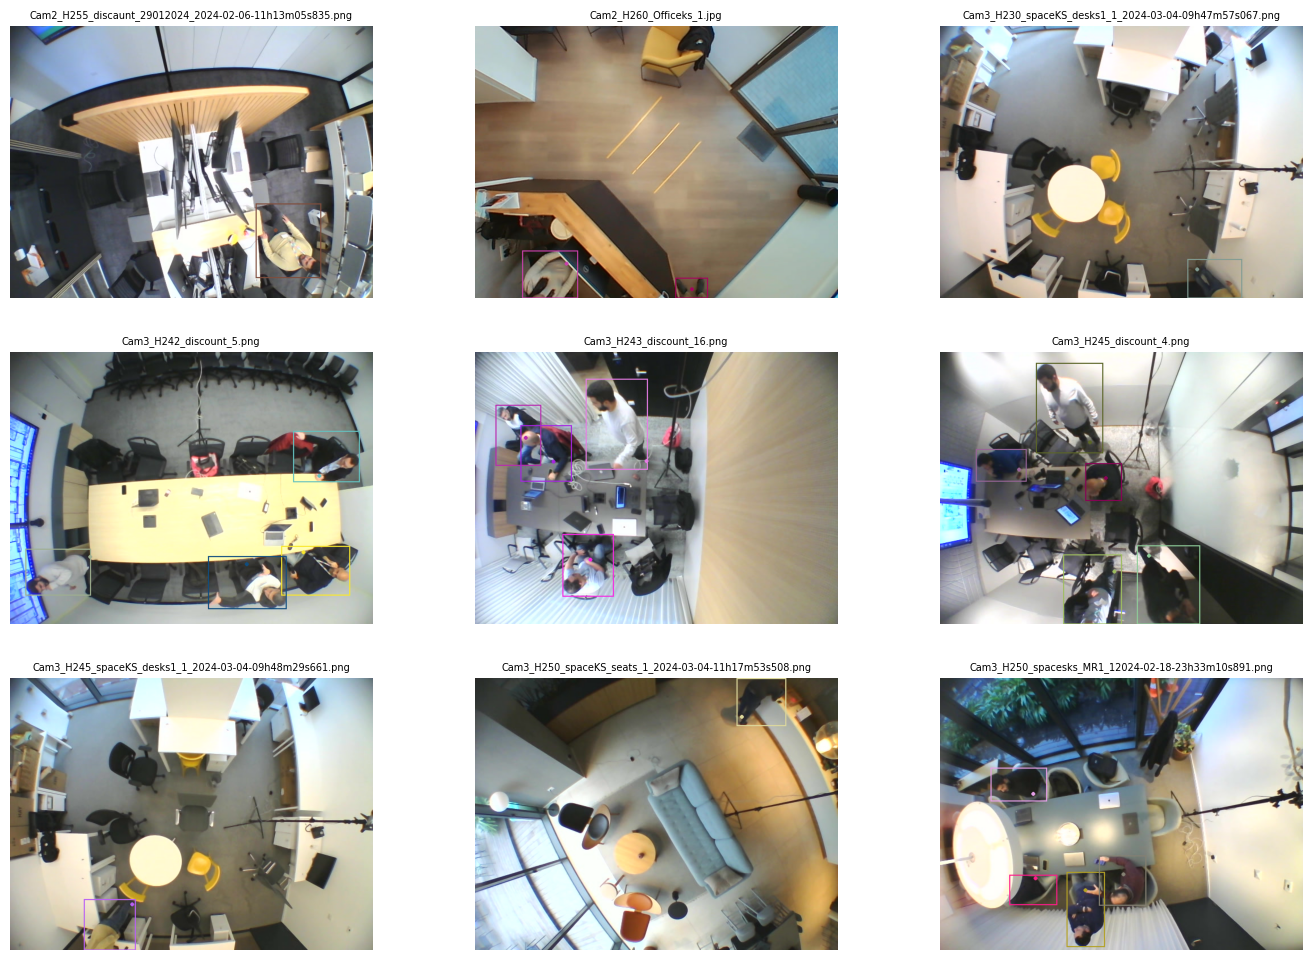

In [7]:
count = 0
N = 9

n_rows = 3
n_cols = 3

plt.figure(figsize=(17, 12))
for image_name, annotation in annotations_person.items():
    image_path = os.path.join("../../data/Telesourcia/Pilot", image_name)  # Adjust this if images are in a different directory
    annotated_image = draw_annotations(image_path, annotation)

    plt.subplot(n_rows, n_cols, count+1)
    plt.imshow(annotated_image)
    plt.title(image_name, fontsize=7)
    plt.axis('off')
    count += 1
    if count == N:
        break

In [8]:
annotation

{'width': 640,
 'height': 480,
 'objects': [{'label': 'Person',
   'bounding_box': [223.27, 342.63, 290.53, 474.56],
   'points': [(256.6, 374.6)],
   'color': (179, 161, 37)},
  {'label': 'Person',
   'bounding_box': [280.15, 313.41, 363.08, 401.66],
   'points': [(323.6, 346.5)],
   'color': (133, 129, 115)},
  {'label': 'Person',
   'bounding_box': [122.51, 347.9, 206.27, 400.25],
   'points': [(168.7, 353.6)],
   'color': (255, 27, 139)},
  {'label': 'Person',
   'bounding_box': [89.14, 158.32, 188.65, 217.92],
   'points': [(164.17, 204.08)],
   'color': (229, 159, 232)}]}